
# CFKS conditioning and regularization study

This notebook studies the numerical conditioning and Tikhonov regularization of CFKS using the first-order oscillatory ODE benchmark
\[
u'(x)=\cos(15x),\qquad x\in[-2\pi,2\pi],\qquad u(0)=0,
\]
with exact solution
\[
u_{\rm ex}(x)=\frac{1}{15}\sin(15x).
\]

Two parameter studies are performed:

1. **Regularization sweep:** vary the relative ridge parameter at fixed kernel width \(\sigma=0.10\).
2. **Kernel-width sweep:** vary \(\sigma\) at the baseline ridge value \(10^{-11}\).

For each case we report the solution RMSE, PDE-residual RMS, boundary error, reduced-system condition number, regularized effective condition number, and numerical rank.


In [1]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import svd
from time import perf_counter

from kapi_onet_publication_style import (
    SINGLE_COLUMN_WIDTH,
    DOUBLE_COLUMN_WIDTH,
    BLUE,
    ORANGE,
    GREEN,
    BLACK,
    GRAY,
    add_major_y_grid,
    save_figure,
)


In [2]:
import numpy as np
from scipy.special import erf

def radical_inverse(n, b=2):
    n = np.asarray(n, dtype=int).copy()
    r = np.zeros_like(n, dtype=float)
    f = 1.0 / b
    while np.any(n > 0):
        r += f * (n % b)
        n //= b
        f /= b
    return r

def rbf1d_uniform_derivs_full(x, y, sigma, ca, cb):
    x = np.asarray(x, dtype=float).reshape(-1, 1)
    y = np.asarray(y, dtype=float).reshape(1, -1)

    m = 0.5*(x+y)
    d = x-y
    A = 0.5*d
    za = ca-m
    zb = cb-m

    Ed = np.exp(-(d**2)/(4*sigma**2))
    ea = np.exp(-(za/sigma)**2)
    eb = np.exp(-(zb/sigma)**2)
    E = erf(zb/sigma)-erf(za/sigma)

    J0 = 0.5*sigma*np.sqrt(np.pi)*E
    J1 = 0.5*sigma**2*(ea-eb)
    J2 = 0.25*sigma**3*np.sqrt(np.pi)*E - 0.5*sigma**2*(zb*eb-za*ea)
    J3 = -0.5*sigma**2*(zb**2*eb-za**2*ea) + sigma**2*J1
    J4 = -0.5*sigma**2*(zb**3*eb-za**3*ea) + 1.5*sigma**2*J2

    C = 1/(cb-ca)
    F = C*Ed

    Iq = A*J0-J1
    Ir = -A*J0-J1
    Iq2 = A**2*J0-2*A*J1+J2
    Ir2 = A**2*J0+2*A*J1+J2
    Iqr = J2-A**2*J0
    Iq2r = -A**3*J0+A**2*J1+A*J2-J3
    Iqr2 = A**3*J0+A**2*J1-A*J2-J3
    Iq2r2 = A**4*J0-2*A**2*J2+J4

    K = F*J0
    K1 = -F*Iq/sigma**2
    K2 = -F*Ir/sigma**2
    K11 = F*(Iq2/sigma**4-J0/sigma**2)
    K22 = F*(Ir2/sigma**4-J0/sigma**2)
    K12 = F*Iqr/sigma**4
    K112 = F*(-Iq2r/sigma**6+Ir/sigma**4)
    K122 = F*(-Iqr2/sigma**6+Iq/sigma**4)
    K1122 = F*(Iq2r2/sigma**8-(Iq2+Ir2)/sigma**6+J0/sigma**4)

    return K,K1,K2,K11,K22,K12,K112,K122,K1122

def compute_kernel_norm(cfg):
    xr = 0.5*(cfg["xL"]+cfg["xR"])
    K = rbf1d_uniform_derivs_full(
        [xr],[xr],cfg["sigma"],cfg["c_a"],cfg["c_b"]
    )[0]
    return float(K[0,0])

def kernel_1d(cfg, x1, x2, type1, type2):
    K,K1,K2,K11,K22,K12,K112,K122,K1122 = rbf1d_uniform_derivs_full(
        x1,x2,cfg["sigma"],cfg["c_a"],cfg["c_b"]
    )
    table = {
        ("val","val"): K,
        ("dx","val"): K1,
        ("val","dx"): K2,
        ("dx","dx"): K12,
        ("dxx","val"): K11,
        ("val","dxx"): K22,
        ("dxx","dx"): K112,
        ("dx","dxx"): K122,
        ("dxx","dxx"): K1122,
    }
    try:
        return table[(type1,type2)] / cfg["norm_const"]
    except KeyError:
        raise ValueError(f"Unsupported functional pair: {type1}, {type2}")

def predict_u(cfg, alpha, xP, bc_x, xq, batch=1000):
    """
    Representation:
      u(q) = sum_j alpha_P[j] d/dy k(q,xP_j)
           + alpha_B k(q,bc_x)
    """
    xq = np.asarray(xq, dtype=float).ravel()
    xP = np.asarray(xP, dtype=float).ravel()
    out = np.zeros_like(xq)
    for i1 in range(0, xq.size, batch):
        ids = slice(i1, min(i1+batch, xq.size))
        q = xq[ids]
        KP = kernel_1d(cfg,q,xP,"val","dx")
        KB = kernel_1d(cfg,q,[bc_x],"val","val")
        out[ids] = np.hstack([KP,KB]) @ alpha
    return out

def predict_ux(cfg, alpha, xP, bc_x, xq, batch=1000):
    xq = np.asarray(xq, dtype=float).ravel()
    xP = np.asarray(xP, dtype=float).ravel()
    out = np.zeros_like(xq)
    for i1 in range(0, xq.size, batch):
        ids = slice(i1, min(i1+batch, xq.size))
        q = xq[ids]
        KP = kernel_1d(cfg,q,xP,"dx","dx")
        KB = kernel_1d(cfg,q,[bc_x],"dx","val")
        out[ids] = np.hstack([KP,KB]) @ alpha
    return out

In [3]:

# ------------------------------ benchmark ------------------------------
omega = 15.0
xL = -2*np.pi
xR =  2*np.pi
bc_x = 0.0
bc_val = 0.0

def rhs_fun(x):
    return np.cos(omega*np.asarray(x, float))

def uexact(x):
    return (1.0/omega)*np.sin(omega*np.asarray(x, float))

# Same deterministic collocation used in the ODE benchmark.
Np = 801
h = radical_inverse(np.arange(1, Np+1), 2)
xP = np.sort(xL + (xR-xL)*h)

pad = 0.75
c_a = xL - pad
c_b = xR + pad

x_test = np.linspace(xL, xR, 5001)
u_ex_test = uexact(x_test)

baseline_sigma = 0.10
baseline_ridge_rel = 1e-11

# Numerical-rank threshold used only as a diagnostic.
rank_tol_rel = 1e-12


In [4]:

def assemble_reduced_system(sigma):
    cfg = {
        "xL": xL, "xR": xR,
        "sigma": float(sigma),
        "c_a": c_a, "c_b": c_b,
    }
    cfg["norm_const"] = compute_kernel_norm(cfg)

    K_PP = kernel_1d(cfg, xP, xP, "dx", "dx")
    K_PB = kernel_1d(cfg, xP, [bc_x], "dx", "val")
    Amat = np.hstack([K_PP, K_PB])
    rhsP = rhs_fun(xP)

    B_P = kernel_1d(cfg, [bc_x], xP, "val", "dx")
    B_B = kernel_1d(cfg, [bc_x], [bc_x], "val", "val")
    Bmat = np.hstack([B_P, B_B])
    bBC = np.array([bc_val])

    alpha_p = np.linalg.pinv(Bmat, rcond=1e-13) @ bBC

    Ub, sB, Vhb = svd(Bmat, full_matrices=True)
    tolB = max(Bmat.shape)*np.finfo(float).eps*np.max(sB)
    rankB = int(np.sum(sB > tolB))
    Q = Vhb.T[:, rankB:]

    Ared = Amat @ Q
    bred = rhsP - Amat @ alpha_p

    Ua, sa, Vha = svd(Ared, full_matrices=False)
    if sa.size == 0 or sa[0] <= 0:
        raise RuntimeError("Reduced CFKS system is singular.")

    return cfg, Amat, Bmat, alpha_p, Q, Ared, bred, Ua, sa, Vha

def solve_from_svd(cfg, alpha_p, Q, Ua, sa, Vha, ridge_rel):
    lam = float(ridge_rel) * sa[0]**2
    filt = sa/(sa**2 + lam)
    eta = Vha.T @ (filt*(Ua.T @ current_bred))
    alpha = alpha_p + Q @ eta
    return alpha, lam

def diagnostics(cfg, alpha, sa, lam):
    u_pred = predict_u(cfg, alpha, xP, bc_x, x_test)
    ux_pred = predict_ux(cfg, alpha, xP, bc_x, x_test)

    err = u_pred - u_ex_test
    res = ux_pred - rhs_fun(x_test)

    rmse = np.sqrt(np.mean(err**2))
    max_error = np.max(np.abs(err))
    res_rms = np.sqrt(np.mean(res**2))
    res_max = np.max(np.abs(res))
    bc_error = abs(float(predict_u(cfg, alpha, xP, bc_x, [bc_x])[0]) - bc_val)

    # Raw condition number of the reduced operator matrix.
    smin = sa[-1]
    cond_raw = np.inf if smin <= 0 else sa[0]/smin

    # Effective condition number of A^T A + lambda I.
    cond_reg = (sa[0]**2 + lam)/(sa[-1]**2 + lam)

    rank_num = int(np.sum(sa > rank_tol_rel*sa[0]))

    return {
        "rmse": rmse,
        "max_error": max_error,
        "res_rms": res_rms,
        "res_max": res_max,
        "bc_error": bc_error,
        "cond_raw": cond_raw,
        "cond_reg": cond_reg,
        "rank": rank_num,
    }



## 1. Regularization sweep at fixed \(\sigma=0.10\)

The reduced matrix and its SVD are formed once. Only the Tikhonov filter changes with the relative ridge parameter.


In [5]:

ridge_values = np.logspace(-16, -4, 13)

cfg0, Amat0, Bmat0, alpha_p0, Q0, Ared0, bred0, Ua0, sa0, Vha0 = assemble_reduced_system(baseline_sigma)
current_bred = bred0

reg_rows = []

for rr in ridge_values:
    lam = rr*sa0[0]**2
    filt = sa0/(sa0**2 + lam)
    eta = Vha0.T @ (filt*(Ua0.T @ bred0))
    alpha = alpha_p0 + Q0 @ eta

    d = diagnostics(cfg0, alpha, sa0, lam)
    d["ridge_rel"] = rr
    d["lambda"] = lam
    reg_rows.append(d)

print("ridge_rel        RMSE          residual RMS    cond_reg       rank")
for d in reg_rows:
    print(
        f'{d["ridge_rel"]:.1e}   '
        f'{d["rmse"]:.3e}   '
        f'{d["res_rms"]:.3e}   '
        f'{d["cond_reg"]:.3e}   '
        f'{d["rank"]:4d}'
    )


ridge_rel        RMSE          residual RMS    cond_reg       rank
1.0e-16   2.044e-07   2.446e-05   1.000e+16    232
1.0e-15   3.012e-07   3.671e-05   1.000e+15    232
1.0e-14   4.561e-07   5.530e-05   1.000e+14    232
1.0e-13   7.113e-07   8.300e-05   1.000e+13    232
1.0e-12   1.099e-06   1.224e-04   1.000e+12    232
1.0e-11   1.702e-06   1.741e-04   1.000e+11    232
1.0e-10   2.713e-06   2.348e-04   1.000e+10    232
1.0e-09   4.456e-06   3.004e-04   1.000e+09    232
1.0e-08   1.093e-05   3.542e-04   1.000e+08    232
1.0e-07   1.196e-04   3.636e-04   1.000e+07    232
1.0e-06   9.149e-04   4.106e-04   1.000e+06    232
1.0e-05   2.391e-03   1.006e-03   1.000e+05    232
1.0e-04   2.780e-03   2.710e-03   1.000e+04    232


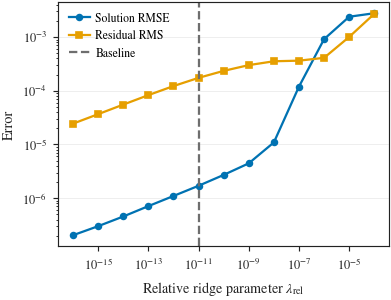

In [6]:

ridge_arr = np.array([d["ridge_rel"] for d in reg_rows])
rmse_arr = np.array([d["rmse"] for d in reg_rows])
res_arr = np.array([d["res_rms"] for d in reg_rows])
condreg_arr = np.array([d["cond_reg"] for d in reg_rows])

fig, ax = plt.subplots(figsize=(SINGLE_COLUMN_WIDTH, 0.78*SINGLE_COLUMN_WIDTH))
ax.loglog(ridge_arr, rmse_arr, "o-", color=BLUE, label="Solution RMSE")
ax.loglog(ridge_arr, res_arr, "s-", color=ORANGE, label="Residual RMS")
ax.axvline(baseline_ridge_rel, linestyle="--", color=GRAY, label="Baseline")
ax.set_xlabel(r"Relative ridge parameter $\lambda_{\rm rel}$")
ax.set_ylabel("Error")
add_major_y_grid(ax)
ax.legend()
fig.tight_layout()
save_figure(fig, "CFKS_regularization_error_sweep")
plt.show()


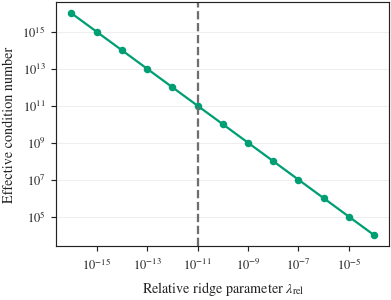

In [7]:

fig, ax = plt.subplots(figsize=(SINGLE_COLUMN_WIDTH, 0.78*SINGLE_COLUMN_WIDTH))
ax.loglog(ridge_arr, condreg_arr, "o-", color=GREEN)
ax.axvline(baseline_ridge_rel, linestyle="--", color=GRAY)
ax.set_xlabel(r"Relative ridge parameter $\lambda_{\rm rel}$")
ax.set_ylabel(r"Effective condition number")
add_major_y_grid(ax)
fig.tight_layout()
save_figure(fig, "CFKS_regularization_conditioning_sweep")
plt.show()



## 2. Kernel-width sweep

Here \(\sigma\) is varied while keeping the center-support interval, collocation set, and relative ridge parameter fixed.


In [8]:

sigma_values = np.array([0.05, 0.065, 0.08, 0.10, 0.125, 0.15, 0.20])

sigma_rows = []

for sig in sigma_values:
    t0 = perf_counter()
    cfg, Amat, Bmat, alpha_p, Q, Ared, bred, Ua, sa, Vha = assemble_reduced_system(sig)

    lam = baseline_ridge_rel*sa[0]**2
    filt = sa/(sa**2 + lam)
    eta = Vha.T @ (filt*(Ua.T @ bred))
    alpha = alpha_p + Q @ eta

    d = diagnostics(cfg, alpha, sa, lam)
    d["sigma"] = sig
    d["lambda"] = lam
    d["elapsed"] = perf_counter() - t0
    sigma_rows.append(d)

print("sigma      RMSE          residual RMS    cond_raw       cond_reg       rank")
for d in sigma_rows:
    print(
        f'{d["sigma"]:.3f}   '
        f'{d["rmse"]:.3e}   '
        f'{d["res_rms"]:.3e}   '
        f'{d["cond_raw"]:.3e}   '
        f'{d["cond_reg"]:.3e}   '
        f'{d["rank"]:4d}'
    )


sigma      RMSE          residual RMS    cond_raw       cond_reg       rank
0.050   4.402e-06   5.657e-04   3.666e+17   1.000e+11    457
0.065   1.575e-06   1.843e-04   4.137e+17   1.000e+11    353
0.080   2.581e-07   1.320e-05   5.928e+17   1.000e+11    288
0.100   1.702e-06   1.741e-04   6.113e+17   1.000e+11    232
0.125   4.968e-06   3.198e-04   4.119e+17   1.000e+11    187
0.150   6.659e-06   3.188e-04   4.035e+17   1.000e+11    157
0.200   3.811e-05   1.567e-03   3.527e+17   1.000e+11    119


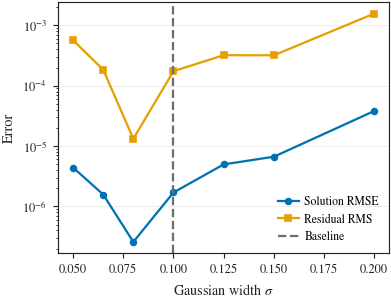

In [9]:

sig_arr = np.array([d["sigma"] for d in sigma_rows])
sig_rmse = np.array([d["rmse"] for d in sigma_rows])
sig_res = np.array([d["res_rms"] for d in sigma_rows])

fig, ax = plt.subplots(figsize=(SINGLE_COLUMN_WIDTH, 0.78*SINGLE_COLUMN_WIDTH))
ax.semilogy(sig_arr, sig_rmse, "o-", color=BLUE, label="Solution RMSE")
ax.semilogy(sig_arr, sig_res, "s-", color=ORANGE, label="Residual RMS")
ax.axvline(baseline_sigma, linestyle="--", color=GRAY, label="Baseline")
ax.set_xlabel(r"Gaussian width $\sigma$")
ax.set_ylabel("Error")
add_major_y_grid(ax)
ax.legend()
fig.tight_layout()
save_figure(fig, "CFKS_sigma_error_sweep")
plt.show()


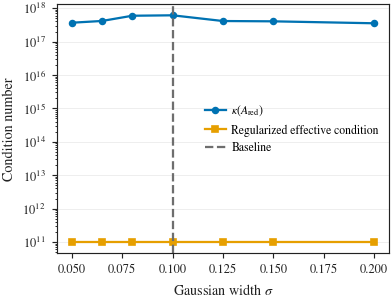

In [10]:

sig_cond_raw = np.array([d["cond_raw"] for d in sigma_rows])
sig_cond_reg = np.array([d["cond_reg"] for d in sigma_rows])
sig_rank = np.array([d["rank"] for d in sigma_rows])

fig, ax = plt.subplots(figsize=(SINGLE_COLUMN_WIDTH, 0.78*SINGLE_COLUMN_WIDTH))
ax.semilogy(sig_arr, sig_cond_raw, "o-", color=BLUE, label=r"$\kappa(A_{\rm red})$")
ax.semilogy(sig_arr, sig_cond_reg, "s-", color=ORANGE, label="Regularized effective condition")
ax.axvline(baseline_sigma, linestyle="--", color=GRAY, label="Baseline")
ax.set_xlabel(r"Gaussian width $\sigma$")
ax.set_ylabel("Condition number")
add_major_y_grid(ax)
ax.legend()
fig.tight_layout()
save_figure(fig, "CFKS_sigma_conditioning_sweep")
plt.show()


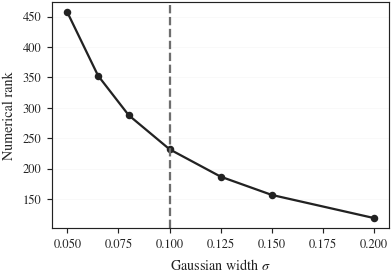

In [11]:

fig, ax = plt.subplots(figsize=(SINGLE_COLUMN_WIDTH, 0.72*SINGLE_COLUMN_WIDTH))
ax.plot(sig_arr, sig_rank, "o-", color=BLACK)
ax.axvline(baseline_sigma, linestyle="--", color=GRAY)
ax.set_xlabel(r"Gaussian width $\sigma$")
ax.set_ylabel("Numerical rank")
ax.grid(True, axis="y", alpha=0.25)
fig.tight_layout()
save_figure(fig, "CFKS_sigma_rank_sweep")
plt.show()



## 3. Publication summary

The following cell prints the baseline quantities and the ridge value that minimizes the solution RMSE in this study. These values can be copied directly into the Results and Discussion section after executing the notebook.


In [12]:

best_reg = min(reg_rows, key=lambda d: d["rmse"])
base_reg = min(reg_rows, key=lambda d: abs(np.log10(d["ridge_rel"]) - np.log10(baseline_ridge_rel)))
base_sig = min(sigma_rows, key=lambda d: abs(d["sigma"] - baseline_sigma))

print("BASELINE:")
print(f"sigma                         = {baseline_sigma:.3f}")
print(f"ridge_rel                     = {baseline_ridge_rel:.1e}")
print(f"solution RMSE                 = {base_reg['rmse']:.6e}")
print(f"residual RMS                  = {base_reg['res_rms']:.6e}")
print(f"raw reduced condition number  = {base_reg['cond_raw']:.6e}")
print(f"regularized condition number  = {base_reg['cond_reg']:.6e}")
print(f"numerical rank                = {base_reg['rank']}")

print("\nBEST RIDGE IN SWEEP:")
print(f"ridge_rel                     = {best_reg['ridge_rel']:.1e}")
print(f"solution RMSE                 = {best_reg['rmse']:.6e}")
print(f"residual RMS                  = {best_reg['res_rms']:.6e}")


BASELINE:
sigma                         = 0.100
ridge_rel                     = 1.0e-11
solution RMSE                 = 1.702406e-06
residual RMS                  = 1.740779e-04
raw reduced condition number  = 6.112543e+17
regularized condition number  = 1.000000e+11
numerical rank                = 232

BEST RIDGE IN SWEEP:
ridge_rel                     = 1.0e-16
solution RMSE                 = 2.044413e-07
residual RMS                  = 2.446175e-05


In [13]:

np.savez_compressed(
    "CFKS_conditioning_regularization_results.npz",
    ridge_values=ridge_arr,
    ridge_rmse=rmse_arr,
    ridge_residual_rms=res_arr,
    ridge_cond_reg=condreg_arr,
    sigma_values=sig_arr,
    sigma_rmse=sig_rmse,
    sigma_residual_rms=sig_res,
    sigma_cond_raw=sig_cond_raw,
    sigma_cond_reg=sig_cond_reg,
    sigma_rank=sig_rank,
    baseline_sigma=baseline_sigma,
    baseline_ridge_rel=baseline_ridge_rel,
    omega=omega,
    Np=Np,
)
print("Saved CFKS_conditioning_regularization_results.npz")


Saved CFKS_conditioning_regularization_results.npz
